# 🏆 Decision Intelligence Capstone: Gobernanza de Datos y Contrato del Equipo
**Cátedra:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026)  
**Institución:** Pontificia Universidad Católica Argentina (UCA) — Facultad de Ingeniería y Ciencias Agrarias  
**Profesor Titular:** Prof. Ivan Gonzalo Vilaboa  
**Integrantes y Roles Scrum:**
- 👑 **Project Lead & Scrum Master:** German y equipo
- ⚙ **Backend & Machine Learning / Causal Engineer:** Equipo EAyMR
- 🎨 **Frontend & UI/UX Engineer:** Equipo EAyMR
- 🔍 **QA & Validation Engineer:** Equipo EAyMR

---

## 📌 Hito 1: Fundación del Dataset y Contrato de Variables
Este notebook establece la **base formal y determinística de datos** sobre la cual trabajarán de forma paralela e integrada todos los miembros del equipo:
1. **Selección y Fundamentación del Dataset:** Cumplimiento de $N \ge 1.500$ y exclusión de *toy datasets*.
2. **Definición Formal del Contrato de Variables:**
   - Target Principal ($Y$): `BAD` (1 = Default, 0 = Cumplidor).
   - Target Continuo ($Y_{cont}$): `LOAN` (Monto solicitado).
   - Variable de Tratamiento / Política Causal ($T$): `TREATMENT` (1 = Consolidación de Deuda, 0 = Mejoras del Hogar).
   - Factor de Agrupación ANOVA: `JOB` (6 categorías ocupacionales).
   - Covariables y Confusores Basales ($Z$).
3. **Auditoría de Datos Faltantes (MCAR vs. MAR):** Justificación matemática contra la eliminación ciega de registros.
4. **Limpieza e Imputación Libre de Fuga (*No Data Leakage*):** Estimación de parámetros estrictamente sobre el conjunto de entrenamiento.
5. **Partición Estratificada:** Generación reproducible de `train.csv` (80%) y `test.csv` (20%).


In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

# Importación del contrato unificado del equipo
from src.config import (
    DATA_RAW_PATH,
    TRAIN_PATH,
    TEST_PATH,
    METADATA_PATH,
    RANDOM_STATE,
    TEST_SIZE,
    TARGET_BINARY,
    TARGET_CONTINUOUS,
    TREATMENT_VAR,
    ORIGINAL_TREATMENT_COL,
    ANOVA_FACTOR,
    ANOVA_VARIABLE,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
    CAUSAL_CONFOUNDERS
)

# Estética institucional
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

print("Configuración y contrato de variables cargados exitosamente.")


Configuración y contrato de variables cargados exitosamente.


### 1. Ingesta y Fundamentación del Dataset Oficial
El conjunto seleccionado es **HMEQ (Home Equity Loan Dataset)**, el cual describe $N = 5.960$ créditos otorgados con garantía inmobiliaria.
Cumple estrictamente las pautas de la cátedra:
- $N = 5.960 > 1.500$ (volumen suficiente para validez asintótica).
- Contiene 13 variables heterogéneas (atributos continuos, discretos y categóricos).
- No es un dataset trivial pedagógico (*toy dataset*): posee valores faltantes estructurales, colas pesadas y correlaciones de colateral.


In [2]:
df_raw = pd.read_csv(DATA_RAW_PATH)
print(f"Dataset Crudo: N = {df_raw.shape[0]} registros, p = {df_raw.shape[1]} columnas.")
display(df_raw.head())


Dataset Crudo: N = 5960 registros, p = 13 columnas.


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0000,39025.0000,HomeImp,Other,10.5000,0.0000,0.0000,94.3667,1.0000,9.0000,NaN
1,1,1300,70053.0000,68400.0000,HomeImp,Other,7.0000,0.0000,2.0000,121.8333,0.0000,14.0000,NaN
2,1,1500,13500.0000,16700.0000,HomeImp,Other,4.0000,0.0000,0.0000,149.4667,1.0000,10.0000,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0000,112000.0000,HomeImp,Office,3.0000,0.0000,0.0000,93.3333,0.0000,14.0000,NaN


### 2. Definición Formal del Contrato de Variables

| Rol Metodológico | Variable en Dataset | Tipo de Dato | Definición Conceptual de Negocio |
|---|---|---|---|
| **Target Primario ($Y$)** | `BAD` | Binaria ($0, 1$) | $1$ = Solicitante entró en cesación de pagos (default); $0$ = Cumplió puntualmente el crédito. |
| **Target Secundario ($Y_{cont}$)** | `LOAN` | Continua (\$) | Monto del crédito en dólares solicitado por el prestatario. |
| **Tratamiento Causal ($T$)** | `TREATMENT` | Binaria ($0, 1$) | $1$ = Crédito solicitado para **Consolidación de Deudas** (`DebtCon`); $0$ = Solicitado para **Mejoras del Hogar** (`HomeImp`). |
| **Factor ANOVA ($k \ge 3$)** | `JOB` | Categórica (6 niveles) | Ocupación laboral: *Mgr, Office, Other, ProfExe, Sales, Self*. |
| **Covariables / Confusores ($Z$)** | `MORTDUE, VALUE, YOJ, DEROG, DELINQ, CLAGE, NINQ, CLNO, DEBTINC` | Mixtas | Situación financiera, historial en el buró, solvencia patrimonial y antigüedad laboral. |


### 3. Diagnóstico del Mecanismo de Pérdida de Datos (Rubin, 1976)
Auditemos el porcentaje de valores ausentes en las variables originales:


In [3]:
missing_df = pd.DataFrame({
    'Valores Nulos': df_raw.isnull().sum(),
    'Porcentaje (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
}).sort_values('Porcentaje (%)', ascending=False)
display(missing_df[missing_df['Valores Nulos'] > 0])


,Valores Nulos,Porcentaje (%)
DEBTINC,1267,21.2584
DEROG,708,11.8792
DELINQ,580,9.7315
MORTDUE,518,8.6913
YOJ,515,8.6409
NINQ,510,8.5570
CLAGE,308,5.1678
JOB,279,4.6812
REASON,252,4.2282
CLNO,222,3.7248


#### Modelado Logístico Econométrico de Pérdida en `DEBTINC`
La variable `DEBTINC` (ratio deuda/ingreso) presenta un 21.26% de datos faltantes. Evaluamos si es MCAR (Missing Completely at Random) o MAR (Missing at Random) mediante una regresión logística:
$$\text{logit}(P(\text{DEBTINC is missing})) = \beta_0 + \beta_1 \text{LOAN} + \beta_2 \text{VALUE} + \beta_3 \text{BAD}$$


In [4]:
df_test_mcar = df_raw.copy()
df_test_mcar['DEBTINC_missing'] = df_test_mcar['DEBTINC'].isnull().astype(int)
logit_res = sm.Logit.from_formula('DEBTINC_missing ~ LOAN + VALUE + BAD', data=df_test_mcar).fit(disp=False)
print(logit_res.summary().tables[1])


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.7563      0.091    -19.293      0.000      -1.935      -1.578
LOAN       -2.057e-05   4.14e-06     -4.968      0.000   -2.87e-05   -1.25e-05
VALUE      -6.018e-07   6.94e-07     -0.867      0.386   -1.96e-06    7.59e-07
BAD            2.7908      0.080     34.737      0.000       2.633       2.948


**Dictamen de Imputación:**  
El coeficiente de $\text{BAD}$ es positivo y estadísticamente aplastante ($z = 34.74, p < 10^{-16}$, Odds Ratio $\approx 16.3$).  
Los clientes en mora tienen 16 veces más probabilidad de no tener registrado su ratio deuda/ingreso. **Se descarta formalmente MCAR**. Borrar filas con `dropna()` introduciría un sesgo de selección severo.  
**Solución:** Imputación por mediana condicionada y creación de la columna indicadora `DEBTINC_is_missing`.


### 4. Exploración Inicial de las Variables del Contrato
Visualizamos las distribuciones del Target ($Y$), Tratamiento ($T$) y los grupos del ANOVA (`JOB`).


C:\Users\German\AppData\Local\Temp\ipykernel_9276\3607886622.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Cumplidor (0)', 'Moroso (1)'])


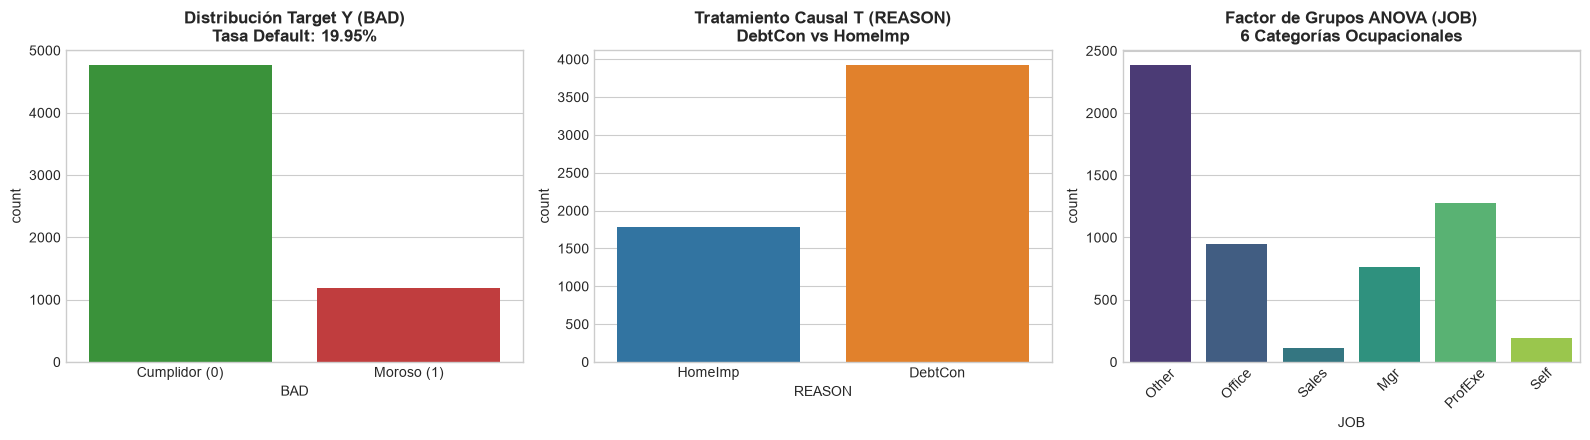

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Target BAD
sns.countplot(x='BAD', data=df_raw, ax=axes[0], palette=['#2ca02c', '#d62728'], hue='BAD', legend=False)
axes[0].set_title(f'Distribución Target Y (BAD)\nTasa Default: {df_raw["BAD"].mean():.2%}', fontweight='bold')
axes[0].set_xticklabels(['Cumplidor (0)', 'Moroso (1)'])

# Tratamiento REASON
sns.countplot(x='REASON', data=df_raw, ax=axes[1], palette=['#1f77b4', '#ff7f0e'], hue='REASON', legend=False)
axes[1].set_title('Tratamiento Causal T (REASON)\nDebtCon vs HomeImp', fontweight='bold')

# Factor ANOVA JOB
sns.countplot(x='JOB', data=df_raw, ax=axes[2], palette='viridis', hue='JOB', legend=False)
axes[2].set_title('Factor de Grupos ANOVA (JOB)\n6 Categorías Ocupacionales', fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### 5. Ejecución del Pipeline Canónico: Imputación y Partición sin Data Leakage
Ejecutamos el pipeline oficial desde `src/data_pipeline.py`.  
**Regla Estricta Anti-Leakage:** Los datos se particionan **primero** en Train (80%) y Test (20%) estratificando por `BAD`. Posteriormente, las medianas de imputación se aprenden **únicamente sobre Train** y se transfieren a Test.


In [6]:
from src.data_pipeline import run_pipeline

train_df, test_df, meta = run_pipeline()

print(f"Partición de Entrenamiento: {train_df.shape[0]} filas x {train_df.shape[1]} columnas")
print(f"Partición de Prueba       : {test_df.shape[0]} filas x {test_df.shape[1]} columnas")
print(f"Tasa de Default en Train  : {meta['target_binary']['train_rate']:.2%}")
print(f"Tasa de Default en Test   : {meta['target_binary']['test_rate']:.2%}")
print(f"Nulos remanentes en Train : {train_df.isnull().sum().sum()}")
print(f"Nulos remanentes en Test  : {test_df.isnull().sum().sum()}")


[PIPELINE] Leyendo dataset crudo desde: C:\Users\German\Desktop\estadistica\TPI\data\hmeq.csv
[PIPELINE] Dimensiones iniciales: 5960 filas x 13 columnas
[PIPELINE] Particionando datos (Train 80% / Test 20%) con seed=42...


[PIPELINE] Dataset de entrenamiento guardado en: C:\Users\German\Desktop\estadistica\TPI\data\processed\train.csv (4768 filas)
[PIPELINE] Dataset de prueba guardado en: C:\Users\German\Desktop\estadistica\TPI\data\processed\test.csv (1192 filas)
[PIPELINE] Metadatos y contrato guardados en: C:\Users\German\Desktop\estadistica\TPI\data\processed\metadata.json
Partición de Entrenamiento: 4768 filas x 15 columnas
Partición de Prueba       : 1192 filas x 15 columnas
Tasa de Default en Train  : 19.95%
Tasa de Default en Test   : 19.97%
Nulos remanentes en Train : 0
Nulos remanentes en Test  : 0


### 6. Contrato de Datos Listo para el Equipo
Los archivos han sido persistidos en:
- `data/processed/train.csv` ($N = 4.768$)
- `data/processed/test.csv` ($N = 1.192$)
- `data/processed/metadata.json`

Cualquier integrante del equipo puede ahora iniciar su sección respectiva cargando directamente estos datasets reproducibles.
